In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import string
import nltk
import spacy
import re

from IPython.display import display, Markdown
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS # sklearn has some stopwords of its own
from nltk.stem import PorterStemmer
from wordcloud import WordCloud

In [68]:
remove_puncts =  '!”#$%&()*+,¦-.:;?@[]\ˆ ‘{|}∼\''
stemmer = PorterStemmer()

nltk.download('stopwords')
nltk_stopwords = set(stopwords.words('english'))

nlp = spacy.load("en_core_web_sm")
spacy_stopwords = nlp.Defaults.stop_words # spacy has some of its own
# Athulya's list, plus some I saw in my WordClouds
filler_words = {"hey", "yeah", "know", "oh", "ohh", "look", "right", "like", "get", "okay", "go",
    "well", "na", "uh", "got", "ok", "gon", "wan", "think", "mean", "say", "see", "ya", "x",
    "come", "gonna", "wanna", "thing", "things", "something", "us", "would", "could", "s",
    "take", "tell", "make", "let", "uhh", "yeahs", "ooh", "ah", "huh", "hi", "yes", "nah",
    "umm", "uhm", "woah", "alright", "somethin", "dunno", "naa", "noooo", "hmm", "e",
    "dude", "man", "guys", "guy", "one", "really", "going", "would", "back", "said", "y'know"}
stopwords_final = nltk_stopwords.union(spacy_stopwords).union(ENGLISH_STOP_WORDS).union(filler_words)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [69]:
scripts_df = pd.read_csv('Friends.csv').astype('string')
print(scripts_df.head())

                                                Text  Speaker  \
0  Originally written by Marta Kauffman and David...     <NA>   
1                          Transcribed by guineapig.     <NA>   
2   CENTRAL PERK. (ALL PRESENT EXCEPT RACHEL AND ...  SCENE 1   
3   There's nothing to tell! He's just some guy I...   MONICA   
4   C'mon, you're going out with the guy! There's...     JOEY   

                                             Episode     Season     Show  
0  Episode-01-The One Where Monica Gets a New Roo...  Season-01  Friends  
1  Episode-01-The One Where Monica Gets a New Roo...  Season-01  Friends  
2  Episode-01-The One Where Monica Gets a New Roo...  Season-01  Friends  
3  Episode-01-The One Where Monica Gets a New Roo...  Season-01  Friends  
4  Episode-01-The One Where Monica Gets a New Roo...  Season-01  Friends  


In [70]:
joey_df = scripts_df[
    scripts_df['Speaker'].str.contains(r'(?i)joey', na = False)
    & ~scripts_df['Speaker'].str.contains(r'(?i)joeys', na = False) # removing stuff like e.g.- "Joey's Sisters" or "Joey's Co-Star"
    & ~scripts_df['Speaker'].str.contains(r'(?i)tojoey', na = False) # removing stuff like "Monica (to Joey)" or "Phoebe (to Joey)"
    & ~scripts_df['Speaker'].str.contains(r'(?i)poster', na = False) # literally one place where Joey apparently turns towards a poster which says [line]
].dropna(subset = ['Text'])

In [71]:
# Keeping just the season and episode numbers
joey_df['Season'] = joey_df['Season'].str.extract(r'Season-(\d+)').astype(int)
joey_df['Episode'] = joey_df['Episode'].str.extract(r'Episode-(\d+)').astype(int)

* spaCy's pipeline already includes tokenisation as the first step ([docs here!](https://spacy.io/usage/processing-pipelines)), so I haven't used NLTK separately.

* POS tagging and NER are also of course included in said pipeline; I only did lowercasing and punctuation after those two were done (as opposed to the project doc's sequence) because I figured capitals and symbols could provide relevant context.

* Note on punctuation removal: spacy's "is_punct" and our provided symbol list have some differences, so I check against both.

* Even though, yes, person's names do count as proper nouns, I felt the question wanted to know about them separately...? So I've tried to remove "person" entities from the noun list.

* I perform stemming on the tokens so that for the word importance task later, words like, say, "waited" and "waiting" don't have different importance scores, and both map to "wait". I know lemmatisation works better for this, and I honestly would have just stuck to that if it weren't for the explicit requirement of Porter Stemming in the first place.

In [72]:
word_counts = []
sentence_counts = []
nouns = []
people = []
stemmed_tokens = []

for doc in nlp.pipe(joey_df['Text'].astype(str), batch_size = 200):

    sentence_counts.append(len(list(doc.sents)))
    word_counts.append(len([t for t in doc if not t.is_punct and not t.is_space
                            and not all(char in remove_puncts for char in t.text)]))

    nouns.append([t.lemma_.lower() for t in doc if t.pos_ in ['NOUN', 'PROPN'] and t.ent_type_ != 'PERSON'
                  and t.text.lower().strip() not in stopwords_final])
    people.append([ent.text.lower() for ent in doc.ents if ent.label_ == 'PERSON'
                   and ent.text.lower().strip() not in stopwords_final])

    stems = [stemmer.stem(t.text.lower()) for t in doc
              if not t.is_stop and not t.is_punct and not t.is_space
              and t.text.lower().strip() not in stopwords_final
              and not all(char in remove_puncts for char in t.text)]
    stemmed_tokens.append(stems)

joey_df['Sentence_Count'] = sentence_counts
joey_df['Word_Count'] = word_counts
joey_df['Extracted_Nouns'] = nouns
joey_df['Extracted_Persons'] = people
joey_df['Stemmed_Tokens'] = stemmed_tokens

# Question 1

In [73]:
episode_totals = joey_df.groupby(['Season', 'Episode'])[['Sentence_Count', 'Word_Count']].sum().reset_index()

# converted all values to ints because partial words or sentences don't really mean much
overall_avg_sents = episode_totals['Sentence_Count'].mean().astype(int)
overall_avg_words = episode_totals['Word_Count'].mean().astype(int)

print(f"Overall Average Sentences per Episode: {overall_avg_sents}")
print(f"Overall Average Words per Episode: {overall_avg_words}")

season_avgs = episode_totals.groupby('Season')[['Sentence_Count', 'Word_Count']].mean().astype(int).reset_index()
print("\nSeason Averages:")
print(season_avgs)

Overall Average Sentences per Episode: 81
Overall Average Words per Episode: 473

Season Averages:
   Season  Sentence_Count  Word_Count
0       1              52         298
1       2              55         358
2       3              63         389
3       4              76         451
4       5              98         545
5       6             100         591
6       7              98         533
7       8             100         567
8       9              85         503
9      10              92         522


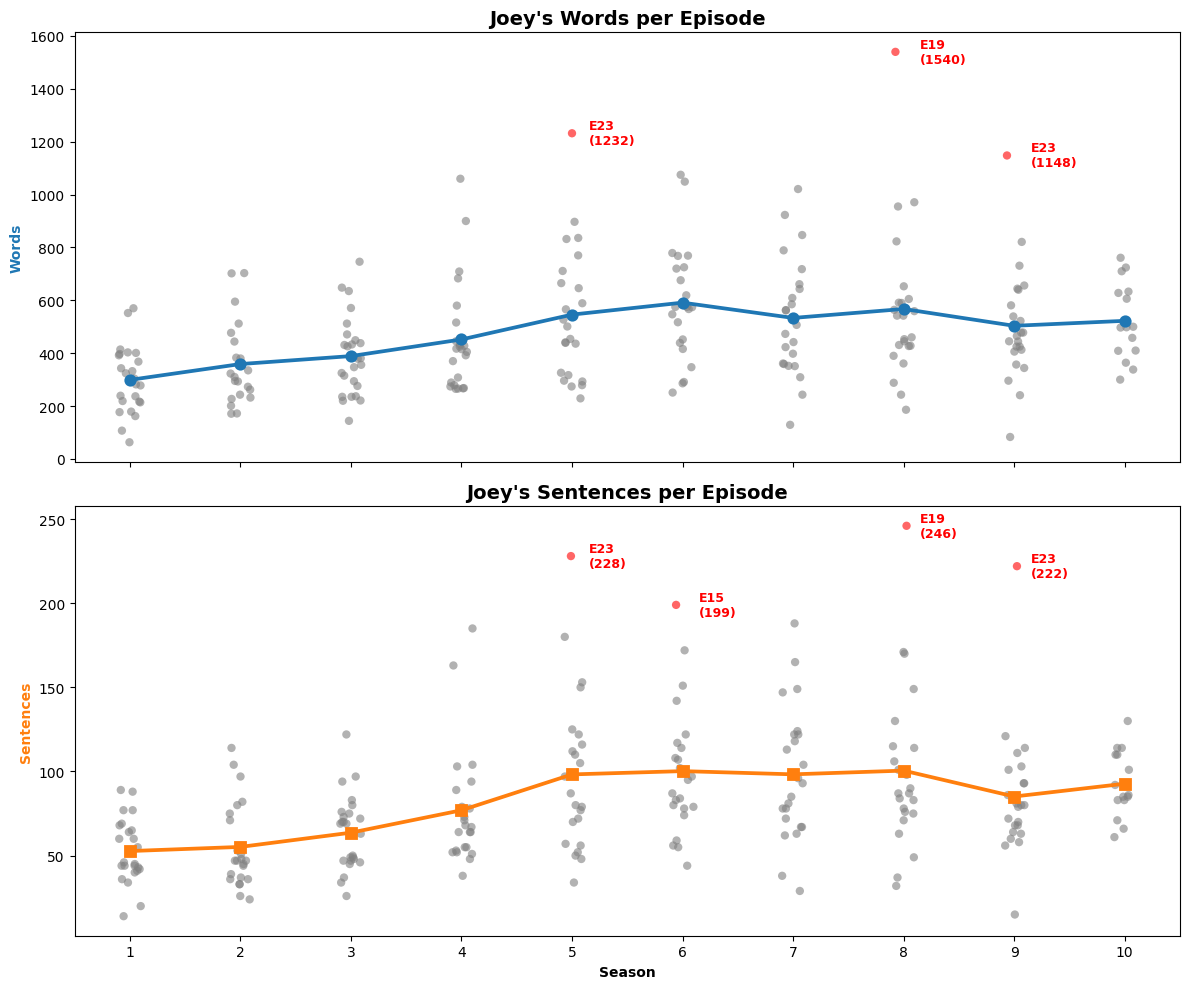

In [74]:
# I set these thresholds myself to highlight some dots that seemed pretty visibly distinctly high
# 1100 and 190 don't have statistical significance to my knowledge
episode_totals['Word_Outlier'] = episode_totals['Word_Count'] > 1100
episode_totals['Sentence_Outlier'] = episode_totals['Sentence_Count'] > 190

seasons = sorted(episode_totals['Season'].unique())
season_to_x = {season: i for i, season in enumerate(seasons)}

def get_ep_label(ep_string):
    match = re.search(r'\d+', str(ep_string))
    return f"E{int(match.group())}"

fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(12, 10), sharex=True)
outlier_palette = {False: 'gray', True: 'red'}

sns.stripplot(
    data=episode_totals, x='Season', y='Word_Count',
    hue='Word_Outlier', palette=outlier_palette,
    alpha=0.6, size=6, jitter=True, ax=ax1, zorder=1, legend=False
)
sns.pointplot(
    data=episode_totals, x='Season', y='Word_Count',
    estimator='mean', color='#1f77b4', errorbar=None,
    markers='o', ax=ax1, zorder=2
)

word_outliers = episode_totals[episode_totals['Word_Outlier']]
for _, row in word_outliers.iterrows():
    x_pos = season_to_x[row['Season']]
    y_pos = row['Word_Count']
    label = f"{get_ep_label(row['Episode'])}\n({int(y_pos)})"

    ax1.text(x_pos + 0.15, y_pos, label, color='red', fontsize=9, va='center', fontweight='bold')

ax1.set_title("Joey's Words per Episode", fontsize=14, fontweight='bold')
ax1.set_ylabel("Words", fontweight='bold', color='#1f77b4')
ax1.set_xlabel('')

sns.stripplot(
    data=episode_totals, x='Season', y='Sentence_Count',
    hue='Sentence_Outlier', palette=outlier_palette,
    alpha=0.6, size=6, jitter=True, ax=ax2, zorder=1, legend=False
)
sns.pointplot(
    data=episode_totals, x='Season', y='Sentence_Count',
    estimator='mean', color='#ff7f0e', errorbar=None,
    markers='s', ax=ax2, zorder=2
)

sent_outliers = episode_totals[episode_totals['Sentence_Outlier']]
for _, row in sent_outliers.iterrows():
    x_pos = season_to_x[row['Season']]
    y_pos = row['Sentence_Count']
    label = f"{get_ep_label(row['Episode'])}\n({int(y_pos)})"

    ax2.text(x_pos + 0.15, y_pos, label, color='red', fontsize=9, va='center', fontweight='bold')

ax2.set_title("Joey's Sentences per Episode", fontsize=14, fontweight='bold')
ax2.set_ylabel("Sentences", fontweight='bold', color='#ff7f0e')
ax2.set_xlabel("Season", fontweight='bold')
ax2.tick_params(axis='x')

fig.tight_layout()
plt.show()

# Question 2

In [75]:
nouns_text = " ".join(joey_df['Extracted_Nouns'].explode().dropna().astype(str))
persons_text = " ".join(joey_df['Extracted_Persons'].explode().dropna().astype(str))

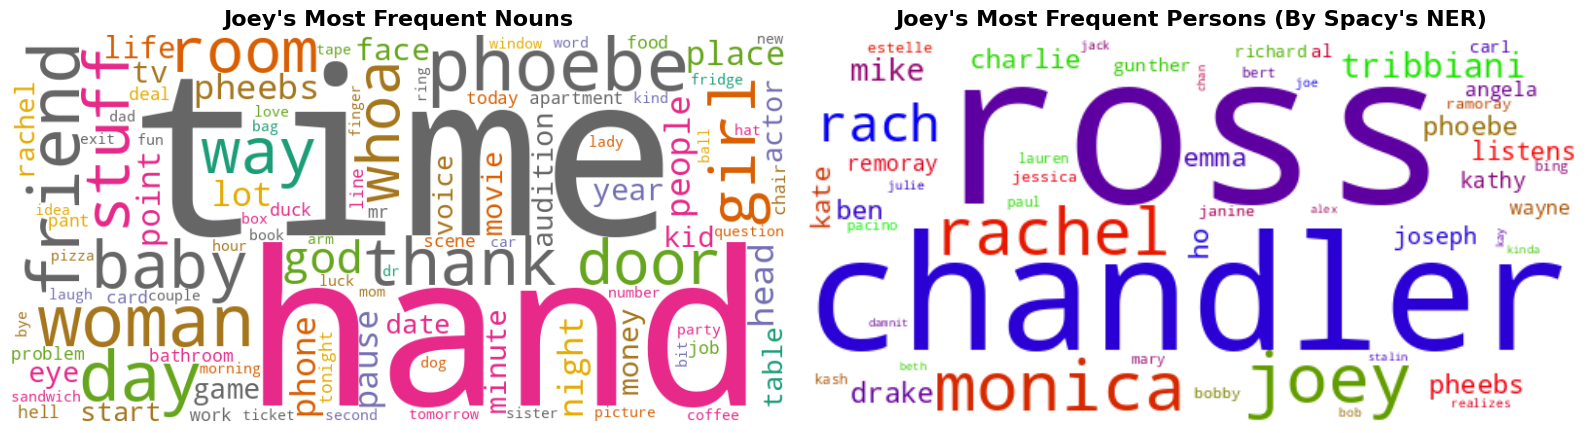

In [76]:
wc_nouns = WordCloud(
    width = 800, height = 400,
    background_color = 'white',
    colormap = 'Dark2',
    max_words = 100,
    collocations = False, # just keeping single words, not bigrams
    stopwords = stopwords_final # our custom list of stopwords
).generate(nouns_text)

wc_persons = WordCloud(
    width = 500, height = 250, # tried to make it smaller because there are less words
    background_color = 'white',
    colormap = 'brg',
    max_words = 50,
    collocations = False,
    stopwords = stopwords_final
).generate(persons_text)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

ax1.imshow(wc_nouns, interpolation='bilinear')
ax1.set_title("Joey's Most Frequent Nouns", fontsize=16, fontweight='bold')
ax1.axis('off')

ax2.imshow(wc_persons, interpolation='bilinear')
ax2.set_title("Joey's Most Frequent Persons (By Spacy's NER)", fontsize=16, fontweight='bold')
ax2.axis('off')

plt.tight_layout()
plt.show()

# Question 3

In [77]:
joey_df['Token_String'] = joey_df['Stemmed_Tokens'].apply(lambda tokens: ' '.join(tokens))

ep_docs = joey_df.groupby(['Season', 'Episode'])['Token_String'].apply(' '.join).reset_index()
sn_docs = joey_df.groupby('Season')['Token_String'].apply(' '.join).reset_index()

In [78]:
tfidf_vect_ep = TfidfVectorizer()
tfidf_vect_sn = TfidfVectorizer(max_df = 0.8) # without max_df, ultra common words are prioritised, which is technically more accurate but less informative

ep_trans = tfidf_vect_ep.fit_transform(ep_docs['Token_String'])
sn_trans = tfidf_vect_sn.fit_transform(sn_docs['Token_String'])

ep_vocab = tfidf_vect_ep.get_feature_names_out()
sn_vocab = tfidf_vect_sn.get_feature_names_out()

overall_scores = np.ravel(ep_trans.sum(axis = 0))
overall_tfidf_dict = dict(zip(ep_vocab, overall_scores))

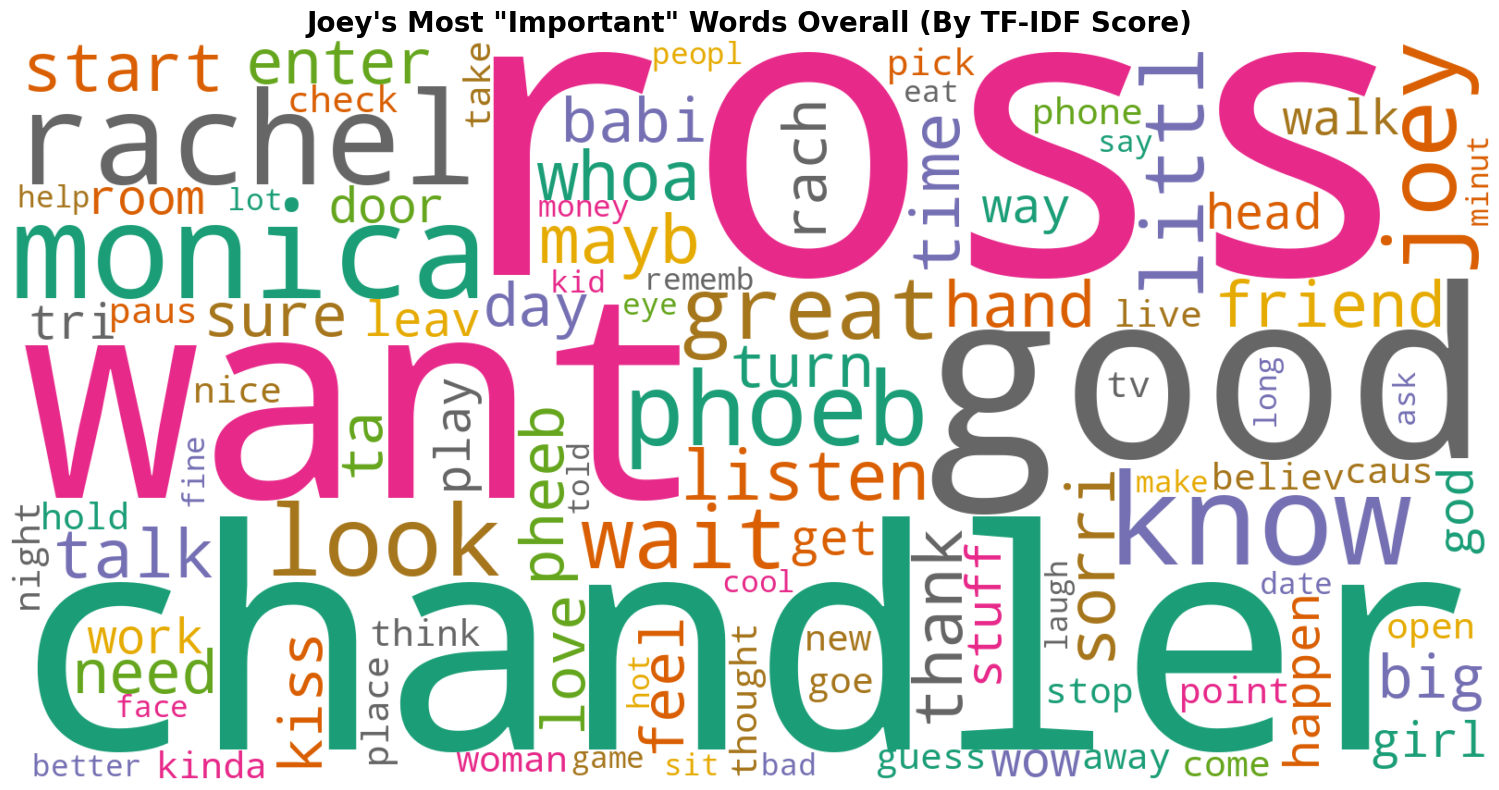

In [79]:
wc_overall = WordCloud(
    width = 1600, height = 800,
    background_color ='white',
    colormap = 'Dark2',
    collocations = False,
    max_words = 100
).generate_from_frequencies(overall_tfidf_dict) # sizes words using weights that the Tfidf thing calculated

plt.figure(figsize=(16, 8))
plt.imshow(wc_overall, interpolation='bilinear')
plt.title("Joey's Most \"Important\" Words Overall (By TF-IDF Score)", fontsize=20, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

In [80]:
def get_imp_words(matrix, features, row_index, top_n):
    row_scores = matrix[row_index].toarray().flatten()
    words = [features[i].capitalize() for i in row_scores.argsort()[::-1]]
    return words[:top_n]

In [81]:
top_n = 5
season_words = {}

for i in range(len(sn_docs)):
    season_num = sn_docs.iloc[i]['Season']

    words = get_imp_words(sn_trans, sn_vocab, row_index=i, top_n=top_n)
    season_words[f"Season {season_num}"] = words

words_df = pd.DataFrame(season_words)
words_df.index = [f"Rank {i+1}" for i in range(top_n)]
display(Markdown("## Joey's 5 Most \"Important\" Words per Season"))
words_df

## Joey's 5 Most "Important" Words per Season

,Season 1,Season 2,Season 3,Season 4,Season 5,Season 6,Season 7,Season 8,Season 9,Season 10
Rank 1,Stalin,Joseph,Kate,Kathi,Soup,Know,Know,Know,Emma,Mike
Rank 2,Ursula,Somethin,Janic,Stripper,Guitar,Wayn,Jessica,Iâ,Mike,Lie
Rank 3,Marcel,Goin,Lauren,Duck,Ben,Thursday,Award,Yâ,Charli,Je
Rank 4,Bob,Juic,Blank,Know,Bag,Carl,Erin,Dina,Hugsi,Hous
Rank 5,Mom,Bracelet,Beth,Map,Emili,Porsch,Yell,Kash,Puzzl,Bert


Referring to the table above: Without the max_df filtering earlier, almost all 10 of the seasons have a basic word like "know" as the "most important" word; which yeah he probably says it a lot but that doesn't tell us anything about the character I think? Because that's a very common thing to say

Referring to the next cell: I have no idea how it renders outside Colab : ) it's supposed to be a regular form with text fields; default values are already filled in so even if one just presses Run All, it will still give an output rather than waiting and stopping execution.

In [82]:
# @title Joey's Most "Important" Words per Episode { display-mode: "form" }
# @markdown Enter the season and episode number, along with how many top words are needed.

Season = 1 # @param {type:"integer"}
Episode = 2 # @param {type:"integer"}
Words = 3 # @param {type:"integer"}

episode_row = ep_docs[(ep_docs['Season'] == Season) & (ep_docs['Episode'] == Episode)]

if not episode_row.empty:
    row_idx = episode_row.index[0]
    top_words = get_imp_words(ep_trans, ep_vocab, row_index = row_idx, top_n = Words)

    print(f"Joey's {Words} most \"important\" words in S{Season:02d}E{Episode:02d} were:", ", ".join(top_words))
else:
    print("\nEpisode not found. Please check your season and episode numbers.")

Joey's 3 most "important" words in S01E02 were: Seriou, Chaotic, Twirli


# Question 4

In [83]:
cv = CountVectorizer(max_features = 500, stop_words = list(stopwords_final))
text_vec = cv.fit_transform(joey_df['Text'])
vocab = cv.get_feature_names_out()

# math, hooray
cooc_matrix = (text_vec.T * text_vec)
cooc_matrix.setdiag(0)

cooc_dense = cooc_matrix.toarray()

total_cooc = np.sum(cooc_dense)
word_totals = np.sum(cooc_dense, axis=1)

with np.errstate(divide='ignore', invalid='ignore'):

    p_xy = cooc_dense / total_cooc
    p_x = word_totals / total_cooc
    p_y = word_totals / total_cooc

    expected_prob = np.outer(p_x, p_y)
    pmi = np.log2(p_xy / expected_prob)
    ppmi = np.maximum(pmi, 0)

ppmi_triu = np.triu(ppmi, k=1)
top_k = 20

flat_indices = np.argsort(ppmi_triu.flatten())[::-1][:top_k]

pairs_data = []
for idx in flat_indices:
    i, j = divmod(idx, ppmi_triu.shape[1])
    score = ppmi_triu[i, j]
    if score > 0:
        pairs_data.append({'Word 1': vocab[i].capitalize(), 'Word 2': vocab[j].capitalize(), 'PPMI Score': round(score, 3)})

ppmi_df = pd.DataFrame(pairs_data)
ppmi_df.index = [f"Pair {i+1}" for i in range(len(ppmi_df))]

display(Markdown("### Joey's Top 20 Word Pairs by PPMI Score"))
display(ppmi_df)

### Joey's Top 20 Word Pairs by PPMI Score

,Word 1,Word 2,PPMI Score
Pair 1,Bet,Lose,8.473
Pair 2,Knicks,Tickets,7.781
Pair 3,Em,Push,7.758
Pair 4,Emma,Hugsy,7.682
Pair 5,Keys,Porsche,7.398
Pair 6,Comin,Parents,7.232
Pair 7,Butt,Shower,7.046
Pair 8,High,School,6.962
Pair 9,Asleep,Fell,6.958
Pair 10,Answer,Clear,6.875
